In this notebook we will compare the predictions from MW11 model with the actual ASTRID measurements of P1D and Px. For that reason the model predictions will be computed using ASTRID cosmology and cddf.

In [1]:
import h5py
from lace.cosmo import cosmology
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from w1_w2 import compute_w1_w2
from matplotlib.lines import Line2D
import scipy.constants
from forestflow import pcross

# Computing P3D first

(In the future, all this should be replaced by calling a function that computes P3D)

In [2]:
wave_log = np.linspace(np.log10(2800), np.log10(6800), 2**12) # Angstrom
wave = 10**wave_log
bias_hcd, bias_lya = 2, -0.18

In [3]:
# ASTRID cosmology
hubble, z = 0.6774, 2.5
ombh2, omegam = 0.0486*(hubble**2), 0.3089
omch2 = omegam*(hubble**2)-ombh2
ns, As = 0.9667, 2.142e-9
Fhcd = 0.9779

cosmo = cosmology.Cosmology()
cosmo.CAMBparams.set_cosmology(H0=100*hubble, ombh2=ombh2, omch2=omch2)
cosmo.CAMBparams.InitPower.set_params(As=As, ns=ns)
print('WARNING: Changed to ASTRID cosmology (It does not affect the f(NHI, X) function)')

In [4]:
data_on = '/pscratch/sd/l/lflores/ASTRID/data/spectra_ASTRID_z2.5_500x500x2500.hdf5'  # With self-shielding

with h5py.File(data_on, 'r') as f:
    print('Keys:', f.keys())
    header_on = f['Header']
    print('------ Header ------')
    for attr in header_on.attrs:
            print(f"{attr} : {header_on.attrs[attr]}")
    print('------ Data ------')
    colden = f['colden/H/1'][:]
    print('colden shape:', colden.shape)

    Lbox = 250  # Mpc/h
    Nsk = int(np.sqrt(colden.shape[0]))  # colden.on_shape[0] gives the size of the axis

Keys: <KeysViewHDF5 ['Header', 'colden', 'spectra', 'tau']>
------ Header ------
Hz : 252.87249366801257
box : 250000.0
discarded : 0
hubble : 0.6774
nbins : 2500
npart : [165988309584 166375000000            0            0  10297622146
     11325619]
omegab : 0.0486
omegal : 0.6911
omegam : 0.3089
redshift : 2.499999947500001
------ Data ------
colden shape: (250000, 2500)


In [5]:
NHirange = np.linspace(17.2, 21.3) 
colden_log = np.log10(colden[colden > 0])
counts, _ = np.histogram(colden_log, bins=NHirange)
mid_nhi = (NHirange[:-1] + (NHirange[1] - NHirange[0])/2)
dn = mid_nhi[1]-mid_nhi[0]

In [6]:
c_kms = scipy.constants.c*1e-3  # kms^-1
dX = (Nsk**2)*Lbox*100*((1+z)**2)/c_kms
fnX = np.interp(NHirange, mid_nhi, counts/dn)/dX
fNHiX = fnX/(np.log(10)*(10**NHirange))

In [7]:
k_w1w2, w1, w2 = compute_w1_w2(wave, NHirange, fNHiX, z, hubble, omegam, resample=True, Mpc=True)
bias_hcd_flux = -2*w2[1]/Fhcd  # Warning, this depends a lot on the cosmology

mu = np.linspace(0, 1, 11)
k = np.logspace(-2.5, 0.5, len(k_w1w2))
k_los = k*mu[:, None]
k_perp = np.sqrt(k**2 - k_los**2)

w1_grid = np.interp(k_los, k_w1w2, w1)
w2_grid = np.interp(k_los, k_w1w2, w2)

plin = cosmo.get_linP_Mpc(z, k)
dkms_dMpc = cosmo.get_dkms_dMpc(z)
k_d = 0.08*dkms_dMpc  # Mpc^-1
exp = np.exp(-(k_los**2/k_d**2))

p3d_hcd = (w2_grid**2)*((bias_hcd+mu[:, None]**2)**2)*plin

# P1D

In [8]:
interp_hcd = RegularGridInterpolator((mu, k), p3d_hcd, bounds_error=False, fill_value=0.0)

kperp = np.logspace(np.log10(k_perp[:-1, 0].min()), np.log10(k_perp[:-1, -1].max()), len(k_perp[0]))
KPAR, KPERP = np.meshgrid(k_w1w2, kperp, indexing='ij')
K = np.sqrt(KPAR**2 + KPERP**2)
MU = KPAR/K
points_target = np.stack([MU.ravel(), K.ravel()], axis=-1)

p3d_hcd_newgrid = interp_hcd(points_target).reshape(K.shape)
p1d_hcd = w1 + np.trapezoid(kperp*p3d_hcd_newgrid, kperp)/(2*np.pi)

In [21]:
data = '/pscratch/sd/l/lflores/astrid_hcd_outputs/p1ds_0.3_21.3.hdf5'

with h5py.File(data, 'r') as f:
    print('Atributes:')
    for m in f.attrs.keys():
        print(f'{m} = {f.attrs[m]}')
    print('----------------') 
    print('Data:')
    print(f.keys())
    k_los = f['k_los'][:]
    print('k_los shape:', k_los.shape)
    p1ds_hcd = f['p1d_hcd'][:]
    print('p1ds_hcd shape:', p1ds_hcd.shape)
    Cs = f['C'][()]
    print('Cs shape = ', Cs.shape)
    mask = f['mask'][:]
    print('mask shape:', mask.shape)

Atributes:
Smoothing factor = 0.3
logNHI_max = 21.3
logNHI_min = 0
minibox_size_Mpch = 250
pixel_width_Mpch = 0.1
pixels_per_skewer = 2500
skewer_separation_Mpch = 0.5
skewers_per_side = 100
----------------
Data:
<KeysViewHDF5 ['C', 'k_los', 'mask', 'p1d_3hcd', 'p1d_3lya', 'p1d_4', 'p1d_hcd', 'p1d_lya', 'p1d_lyahcd', 'p1d_tot']>
k_los shape: (1251,)
p1ds_hcd shape: (25, 1251)
Cs shape =  (25,)
mask shape: (10000,)


WARNING: p1ds are in Mpc/h units and k_los in h/Mpc

In [22]:
k_los *= hubble  # In Mpc^-1
p1ds_hcd /= hubble
P1d_hcd, P1d_std_hcd = np.mean(p1ds_hcd, axis=0), np.std(p1ds_hcd, axis=0)/np.sqrt(p1ds_hcd.shape[0]-1)

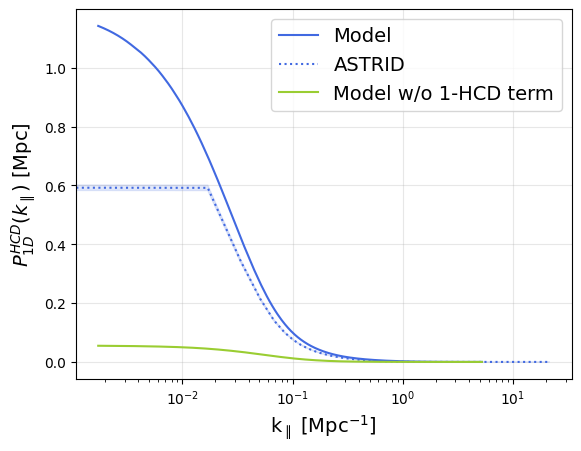

In [24]:
plt.plot(k_w1w2, p1d_hcd, color='royalblue', label='Model')
plt.plot(k_los, P1d_hcd, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_hcd-P1d_std_hcd), (P1d_hcd+P1d_std_hcd), color='royalblue', alpha=0.15)
plt.plot(k_w1w2, p1d_hcd-w1, color='yellowgreen', label='Model w/o 1-HCD term')

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
#plt.xlim(k_los[1:].min(), 6)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

In [27]:
res_hcd = (np.abs(np.interp(k_w1w2, k_los, P1d_hcd)[1:] - p1d_hcd[1:])/p1d_hcd[1:])

/tmp/ipykernel_200670/529186293.py:1: RuntimeWarning: divide by zero encountered in divide
  res_hcd = (np.abs(np.interp(k_w1w2, k_los, P1d_hcd)[1:] - p1d_hcd[1:])/p1d_hcd[1:])


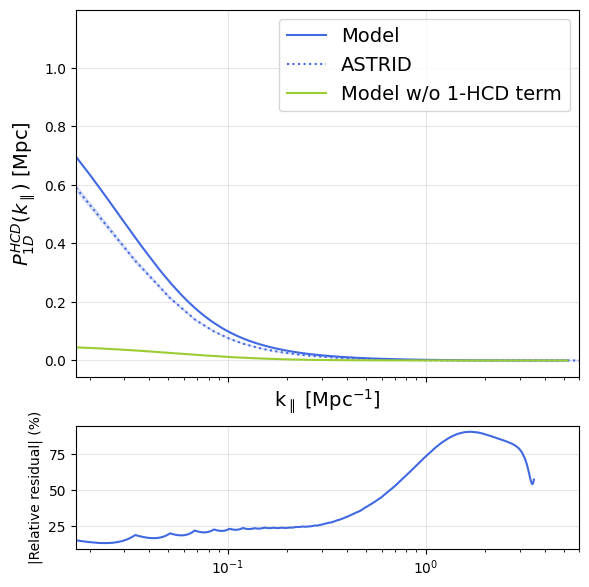

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 7), sharex='col',
                         gridspec_kw={'height_ratios': [3, 1]}, )

# Upper panel
ax = axes[0]
ax.plot(k_w1w2, p1d_hcd, color='royalblue', label='Model')
ax.plot(k_los, P1d_hcd, color='royalblue', linestyle=':', label='ASTRID')
ax.fill_between(k_los, (P1d_hcd-P1d_std_hcd), (P1d_hcd+P1d_std_hcd), color='royalblue', alpha=0.15)
ax.plot(k_w1w2, p1d_hcd-w1, color='yellowgreen', label='Model w/o 1-HCD term')

ax.legend(loc='upper right', fontsize=14)
ax.set_xscale('log')
ax.grid(alpha=0.3)
ax.set_xlim(k_los[1:].min(), 6)

ax.set_xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
ax.set_ylabel(r'$P_{1D}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)

# Lower pannel
ax = axes[1]
ax.plot(k_w1w2[1:], np.abs(res_hcd)*100, color='royalblue')
ax.set_ylabel('|Relative residual| (%)')
ax.grid(alpha=0.3)

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

# Px

In [49]:
cosmo_dict = {
    'H0': 100*hubble,
    'ombh2': ombh2,
    'omch2': omch2,
    'ns': ns,
    'As': As}

r_bins = [0.6, 1.09, 1.97, 3.58, 6.5, 11.8]

In [34]:
def P3D_hcd_model(z, k, mu, p3d_params, new_cosmo_params):

    cosmo = cosmology.Cosmology(cosmo_params_dict=new_cosmo_params)
    plin = cosmo.get_linP_Mpc(z, k)

    kpar = k * mu
    w2_eval = np.interp(kpar, k_w1w2, w2)

    p3d_hcd = (w2_eval**2)*((bias_hcd+mu**2)**2)*plin

    return p3d_hcd

P3D_hcd_model.coordinates = 'k_mu'

In [50]:
px_hcd = []
for i in np.arange(len(r_bins)-1):  
    r_effs = np.linspace(r_bins[i], r_bins[i+1], 10)
    px_hcd_eff = pcross.Px_Mpc_detailed([2.5], k_w1w2, r_effs, P3D_hcd_model, max_kperp=10.0**2, p3d_params=cosmo_dict, new_cosmo_params=cosmo_dict)
    px_hcd.append(np.average(px_hcd_eff, axis=1, weights=r_effs))
px_hcd = np.array(px_hcd)

In [51]:
data = '/pscratch/sd/l/lflores/astrid_hcd_outputs/pxs_0.3_21.3.hdf5'

with h5py.File(data, 'r') as f:
    print('Atributes:')
    for m in f.attrs.keys():
        print(f'{m} = {f.attrs[m]}')
    logNHI_min = f.attrs['logNHI_min']
    logNHI_max = f.attrs['logNHI_max']
    Lbox = f.attrs['box_size_Mpch']
    Lmbox = f.attrs['minibox_size_Mpch']
    print('----------------') 
    print('Data:')
    print(f.keys())
    k_los = f['k_los'][:]
    print('k_los shape:', k_los.shape)
    pxs_hcd = f['px_hcd'][:]
    print('px_hcd shape:', pxs_hcd.shape)
    Cs = f['C'][()]
    print('Cs shape = ', Cs.shape)
    rbins = f['r_bins'][:]

Atributes:
----- WARNING ----- = Units in terms of h
Smoothing factor = 0.3
box_size_Mpch = 250
logNHI_max = 21.3
logNHI_min = 0
minibox_size_Mpch = 50.0
pixel_width_Mpch = 0.1
pixels_per_skewer = 2500
skewer_separation_Mpch = 0.5
skewers_per_side = 100
----------------
Data:
<KeysViewHDF5 ['C', 'Mask', 'k_los', 'px_3hcd', 'px_3lya', 'px_4', 'px_hcd', 'px_lya', 'px_lyahcd', 'px_tot', 'r_bins']>
k_los shape: (315,)
px_hcd shape: (25, 5, 315)
Cs shape =  (25,)


In [52]:
k_los *= hubble  # In Mpc^-1
rbins /= hubble  # In Mpc
pxs_hcd /= hubble 

Let's make the mean of all the boxes

In [53]:
Nmbox = pxs_hcd[:, 0].shape[0]
Px_hcd, Px_std_hcd = np.mean(pxs_hcd, axis=0), np.std(pxs_hcd, axis=0)/np.sqrt(Nmbox-1)

In [54]:
k_los, Px_hcd, Px_std_hcd = k_los[1:], Px_hcd[:, 1:], Px_std_hcd[:, 1:]

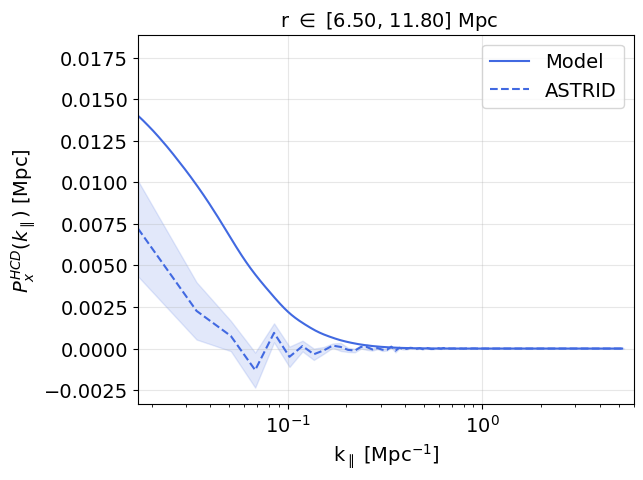

In [55]:
i = 4
plt.plot(k_w1w2, px_hcd[i, 0, :], color='royalblue', label='Model')
plt.plot(k_los, Px_hcd[i, :], color='royalblue', linestyle='--', label='ASTRID')
plt.fill_between(k_los, (Px_hcd[i]-Px_std_hcd[i]), (Px_hcd[i]+Px_std_hcd[i]), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)

plt.xscale('log')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(alpha=0.3)
plt.xlim(k_los.min(), 6)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{x}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)
plt.title(f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]), fontsize=14);

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

/tmp/ipykernel_259420/3609748382.py:5: RuntimeWarning: divide by zero encountered in divide
  res_hcd = (np.abs(np.interp(k_w1w2, k_los, Px_hcd[i, :])) - px_hcd[i, 0, :])/px_hcd[i, 0, :]


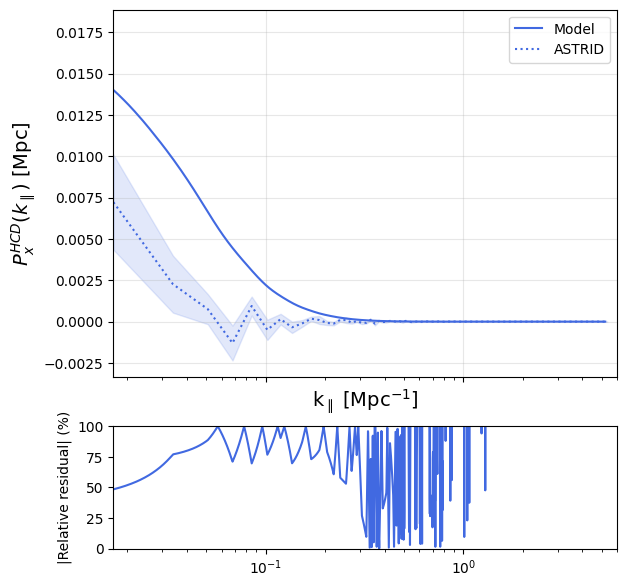

In [56]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 7), sharex='col',
                         gridspec_kw={'height_ratios': [3, 1]}, )

i = 4
res_hcd = (np.abs(np.interp(k_w1w2, k_los, Px_hcd[i, :])) - px_hcd[i, 0, :])/px_hcd[i, 0, :]

# Upper panel
ax = axes[0]
ax.plot(k_w1w2, px_hcd[i, 0, :], color='royalblue', label='Model')
ax.plot(k_los, Px_hcd[i, :], color='royalblue', linestyle=':', label='ASTRID')
ax.fill_between(k_los, (Px_hcd[i, :]-Px_std_hcd[i, :]), (Px_hcd[i, :]+Px_std_hcd[i, :]), color='royalblue', alpha=0.15)

ax.legend(loc='upper right')
ax.set_xscale('log')
ax.grid(alpha=0.3)
ax.set_xlim(k_los.min(), 6)
#ax.set_ylim(-0.2, 0.4)
ax.set_xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
ax.set_ylabel(r'$P_{x}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)

# Lower pannel
ax = axes[1]
ax.plot(k_w1w2, np.abs(res_hcd)*100, color='royalblue')
ax.set_ylabel('|Relative residual| (%)')
ax.set_ylim(0, 100);

plt.savefig('plot.png', dpi=200, bbox_inches='tight')